# Demo 3: Visual Question Answering

**Task:** Ask free-form natural language questions about an image

---
**Flow:**
1. Load an image from file
2. Load Qwen-VL model
3. Generate auto caption or ask custom questions


In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import os
# GPU Setting
os.environ['CUDA_VISIBLE_DEVICES'] = '2'
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
from PIL import Image
import cv2


import warnings
warnings.filterwarnings('ignore')

## Step 1: Load Image

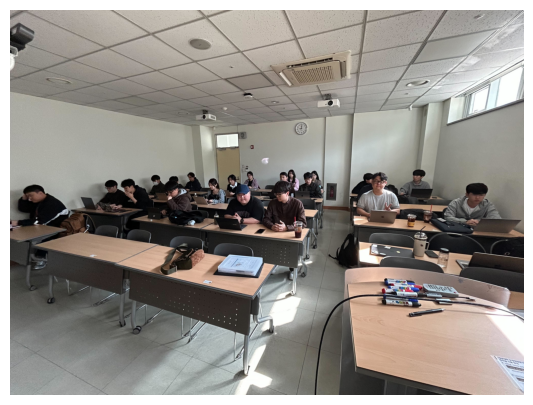

In [3]:
# ── Load from file ──────────────────────────────────────────────────
IMAGE_PATH = "xai506_example_image.jpg"
image = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(7, 5))
plt.imshow(image); plt.axis('off'); plt.show()

## Step 2: Load Qwen2-VL Model

In [2]:
from models.vlm_model import Qwen2VLQA

vlm = Qwen2VLQA()
vlm.load()   # downloads model on first run (~15 GB)

[Qwen2-VL] Loading Qwen/Qwen2-VL-7B-Instruct ...


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
You have video processor config saved in `preprocessor.json` file which is deprecated. Video processor configs should be saved in their own `video_preprocessor.json` file. You can rename the file or load and save the processor back which renames it automatically. Loading from `preprocessor.json` will be removed in v5.0.


Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

[Qwen2-VL] Model loaded.


## Step 3: Auto Image Caption

Ask the model to describe the image without a specific question.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


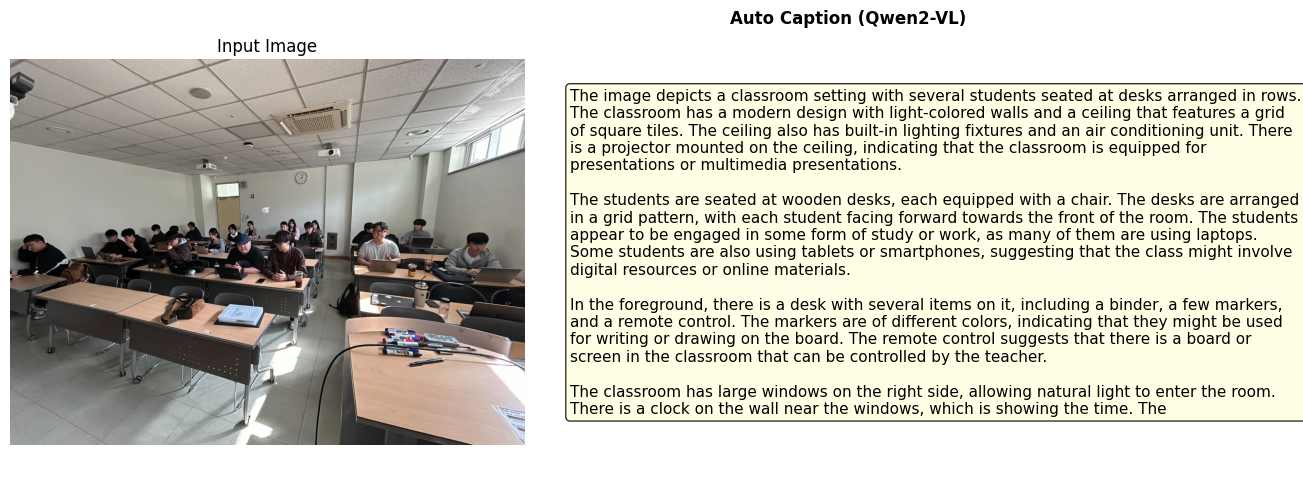


[Caption]
The image depicts a classroom setting with several students seated at desks arranged in rows. The classroom has a modern design with light-colored walls and a ceiling that features a grid of square tiles. The ceiling also has built-in lighting fixtures and an air conditioning unit. There is a projector mounted on the ceiling, indicating that the classroom is equipped for presentations or multimedia presentations.

The students are seated at wooden desks, each equipped with a chair. The desks are arranged in a grid pattern, with each student facing forward towards the front of the room. The students appear to be engaged in some form of study or work, as many of them are using laptops. Some students are also using tablets or smartphones, suggesting that the class might involve digital resources or online materials.

In the foreground, there is a desk with several items on it, including a binder, a few markers, and a remote control. The markers are of different colors, indicati

In [8]:
caption = vlm.caption(image)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].imshow(image); axes[0].axis('off'); axes[0].set_title("Input Image")
axes[1].axis('off')
axes[1].set_title("Auto Caption (Qwen2-VL)", fontweight='bold')
axes[1].text(0.05, 0.5, caption, transform=axes[1].transAxes,
             fontsize=11, va='center', wrap=True,
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
plt.tight_layout()
plt.show()

print("\n[Caption]")
print(caption)

## Step 4: Ask a Question

Enter any question about the image.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


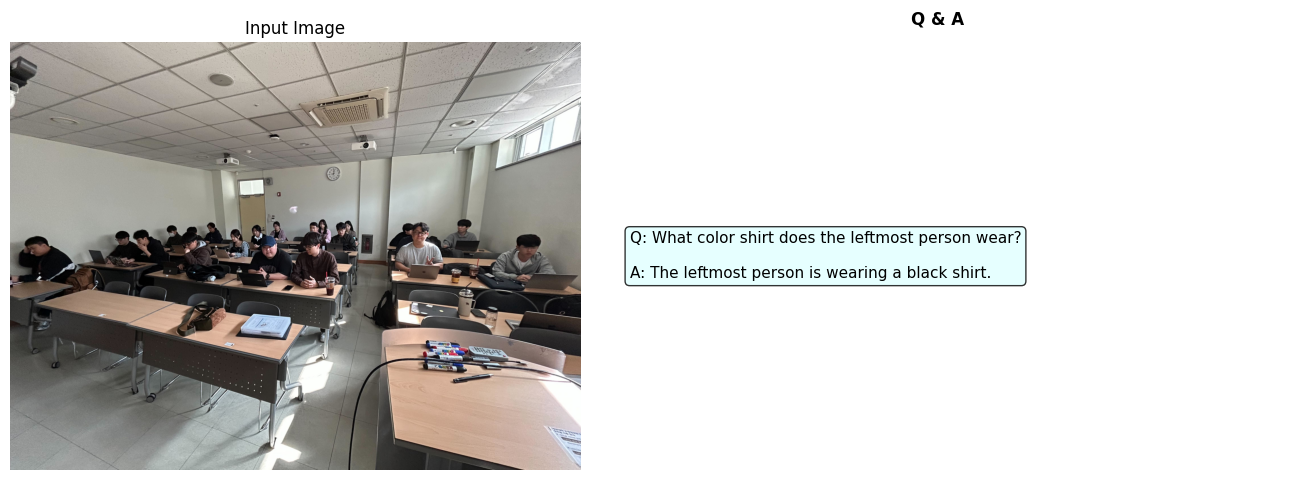

Q: What color shirt does the leftmost person wear?
A: The leftmost person is wearing a black shirt.


In [7]:
# ─── Change the question here ────────────────────────────────────────────────
QUESTION = "What color shirt does the leftmost person wear?"
# QUESTION = "How many people are in the classroom?"
# ─────────────────────────────────────────────────────────────────────────────

answer = vlm.answer(image, QUESTION)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].imshow(image); axes[0].axis('off'); axes[0].set_title("Input Image")
axes[1].axis('off')
axes[1].set_title("Q & A", fontweight='bold')
qa_text = f"Q: {QUESTION}\n\nA: {answer}"
axes[1].text(0.05, 0.5, qa_text, transform=axes[1].transAxes,
             fontsize=11, va='center', wrap=True,
             bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.8))
plt.tight_layout()
plt.show()

print(f"Q: {QUESTION}")
print(f"A: {answer}")